# 18. Noise Interaction Model (`hour * weekday`)

**Topic**: Extending the Brooklyn hourly noise regression model from additive `hour + weekday` indicators (v1) to a full `hour * weekday` interaction specification (v2) to capture late-night weekend spillover and weekday asymmetry.

- **Inputs**:
  - `data/processed/complaints_clean.csv` (211,843 noise rows; 11 midnight placeholders excluded -> 8,760 hourly grid)
  - `models/noise_model.joblib` (frozen v1 additive baseline, read-only)
- **Outputs**:
  - `models/noise_model_v2.joblib` (frozen v2 interaction model bundle)
  - `report/figures/18_noise_interaction_profiles.png`
  - `report/figures/18_fold_mae_comparison.png`
- **Runtime**: < 15 seconds

In [1]:
import sys; from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "environment.yml").exists()); sys.path.insert(0, str(ROOT))
import warnings
warnings.filterwarnings("ignore")
from src.nbutils import Checker
import hashlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Configuration Flags
RUN_HEAVY = False
RUN_API = False


In [2]:
# Section 1: Hourly Noise Grid & Interaction Feature Schema
from src.models.regression import build_noise_hourly

complaints_df = pd.read_csv(
    ROOT / "data/processed/complaints_clean.csv",
    dtype={"id": str, "resolution_id": str},
    keep_default_na=False,
)

hourly_df, meta = build_noise_hourly(
    complaints_df,
    start_date="2025-11-01",
    end_date="2026-10-31",
    include_interactions=True,
)

print(f"Grid rows: {len(hourly_df):,} (365 days x 24 hours)")
print(f"Additive features:    {len(meta['hour_features']) + len(meta['weekday_features'])} (23 hour + 6 weekday)")
print(f"Interaction features: {len(meta['interaction_features'])} (23 hour x 6 weekday)")
print(f"Total model features: {len(meta['all_features'])} (+1 intercept = 168 cell means)")


build_noise_hourly: Excluded 11 midnight placeholder rows (0.0052%)
Weekday encoding in complaints_clean.csv: 0=Monday, 1=Tuesday, 2=Wednesday, 3=Thursday, 4=Friday, 5=Saturday, 6=Sunday.


build_noise_hourly: Reindexed to 8,760 hours. Zero-count hours: 1
Grid rows: 8,760 (365 days x 24 hours)
Additive features:    29 (23 hour + 6 weekday)
Interaction features: 138 (23 hour x 6 weekday)
Total model features: 167 (+1 intercept = 168 cell means)


In [3]:
# Section 2: Chronological 80/20 & Rolling-Origin Evaluation (Additive vs Interaction)
from src.models.regression import evaluate_and_train_noise_interaction

v2_path = ROOT / "models/noise_model_v2.joblib"
eval_res = evaluate_and_train_noise_interaction(
    hourly_df,
    model_path=v2_path,
    save=True,
)

chrono_df = pd.DataFrame([eval_res["chrono_additive"], eval_res["chrono_interaction"]])
chrono_imp = (
    (eval_res["chrono_additive"]["mae"] - eval_res["chrono_interaction"]["mae"])
    / eval_res["chrono_additive"]["mae"]
    * 100.0
)

print("=== Chronological 80/20 Split Comparison ===")
print(chrono_df.to_string(index=False, formatters={
    "mae": "{:.4f}".format, "rmse": "{:.4f}".format, "r2": "{:.4f}".format
}))
print(f"Chrono MAE reduction: {eval_res['chrono_additive']['mae'] - eval_res['chrono_interaction']['mae']:.4f} ({chrono_imp:+.2f}%)")

folds_df = pd.DataFrame(eval_res["fold_records"])
n_improved_folds = int(folds_df["improved"].sum())
print("\n=== Rolling-Origin Monthly Folds (2026-03 .. 2026-10) ===")
print(folds_df.to_string(index=False, formatters={
    "mae_additive": "{:.4f}".format,
    "mae_interaction": "{:.4f}".format,
    "r2_additive": "{:.4f}".format,
    "r2_interaction": "{:.4f}".format,
    "rel_improvement_pct": "{:+.2f}%".format,
}))

pooled_df = pd.DataFrame([eval_res["pooled_additive"], eval_res["pooled_interaction"]])
pooled_imp = (
    (eval_res["pooled_additive"]["mae"] - eval_res["pooled_interaction"]["mae"])
    / eval_res["pooled_additive"]["mae"]
    * 100.0
)
print("\n=== Pooled Rolling-Origin Summary (N=5,880 hours) ===")
print(pooled_df.to_string(index=False, formatters={
    "mae": "{:.4f}".format, "rmse": "{:.4f}".format, "r2": "{:.4f}".format
}))
print(f"Pooled MAE reduction: {eval_res['pooled_additive']['mae'] - eval_res['pooled_interaction']['mae']:.4f} ({pooled_imp:+.2f}%)")
print(f"Folds improved: {n_improved_folds} / {len(folds_df)}")
print(f"Saved v2 model to: {eval_res['saved_path'].relative_to(ROOT)}")


=== Chronological 80/20 Split Comparison ===
                       model     mae    rmse     r2  n_test
   Additive (hour + weekday) 10.8866 19.9852 0.4872    1752
Interaction (hour * weekday)  9.6297 17.1376 0.6229    1752
Chrono MAE reduction: 1.2569 (+11.55%)

=== Rolling-Origin Monthly Folds (2026-03 .. 2026-10) ===
  month  n_hours mae_additive mae_interaction r2_additive r2_interaction rel_improvement_pct  improved
2026-03      744       7.6499          7.0331      0.5249         0.5802              +8.06%      True
2026-04      720       7.6382          6.8827      0.5424         0.6410              +9.89%      True
2026-05      744      12.8610         12.2832      0.3385         0.4167              +4.49%      True
2026-06      720      10.5828         10.0700      0.4954         0.5542              +4.85%      True
2026-07      744       8.2338          7.4371      0.6055         0.7092              +9.68%      True
2026-08      744       9.8874          8.4071      0.5255  

In [4]:
# Section 3: Prediction Cell Comparison (predict_noise v1 vs predict_noise_v2)
from src.models.regression import predict_noise, predict_noise_v2, load_noise_model, load_noise_model_v2

v1_path = ROOT / "models/noise_model.joblib"
bundle_v1 = load_noise_model(v1_path)
bundle_v2 = load_noise_model_v2(v2_path)

day_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
cell_rows = []
obs_means = hourly_df.groupby(["weekday", "hour"])["count"].mean().to_dict()

for w in range(7):
    for h in range(24):
        p_v1 = predict_noise(hour=h, weekday=w, model_path=v1_path)
        p_v2 = predict_noise_v2(hour=h, weekday=w, model_path=v2_path)
        obs = float(obs_means[(w, h)])
        cell_rows.append({
            "weekday": w,
            "day": day_names[w],
            "hour": h,
            "observed_mean": obs,
            "pred_v1_additive": p_v1,
            "pred_v2_interaction": p_v2,
            "diff_v2_minus_v1": p_v2 - p_v1,
        })

comp_df = pd.DataFrame(cell_rows)
print("=== Top 10 Largest Upward Adjustments (Interaction > Additive) ===")
print(comp_df.sort_values("diff_v2_minus_v1", ascending=False).head(10).to_string(index=False, formatters={
    "observed_mean": "{:.2f}".format,
    "pred_v1_additive": "{:.2f}".format,
    "pred_v2_interaction": "{:.2f}".format,
    "diff_v2_minus_v1": "{:+.2f}".format,
}))

print("\n=== Top 10 Largest Downward Adjustments (Interaction < Additive) ===")
print(comp_df.sort_values("diff_v2_minus_v1", ascending=True).head(10).to_string(index=False, formatters={
    "observed_mean": "{:.2f}".format,
    "pred_v1_additive": "{:.2f}".format,
    "pred_v2_interaction": "{:.2f}".format,
    "diff_v2_minus_v1": "{:+.2f}".format,
}))


=== Top 10 Largest Upward Adjustments (Interaction > Additive) ===
 weekday day  hour observed_mean pred_v1_additive pred_v2_interaction diff_v2_minus_v1
       6 Sun     0        101.31            57.94              101.31           +43.37
       5 Sat    23        105.98            69.99              105.98           +35.99
       6 Sun     1         71.54            41.81               71.54           +29.73
       5 Sat    22        101.74            74.03              101.74           +27.70
       4 Fri    23         79.17            58.49               79.17           +20.68
       6 Sun     2         43.94            29.33               43.94           +14.61
       5 Sat     0         73.17            59.78               73.17           +13.39
       5 Sat     1         53.83            43.65               53.83           +10.18
       4 Fri    22         70.23            62.54               70.23            +7.69
       6 Sun     3         28.73            22.73              

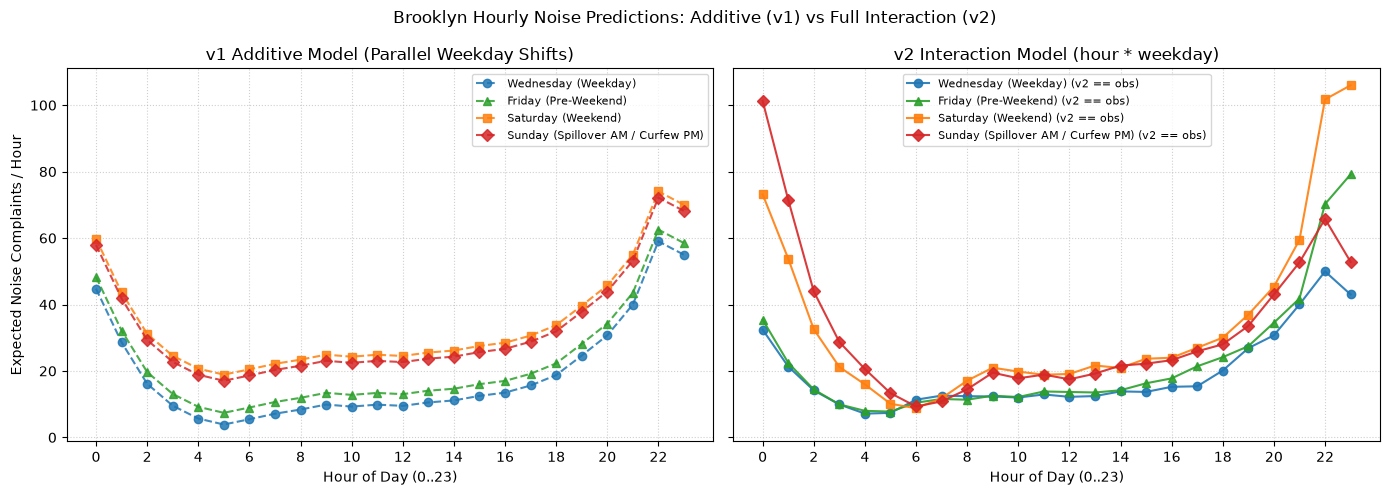

Saved: report\figures\18_noise_interaction_profiles.png


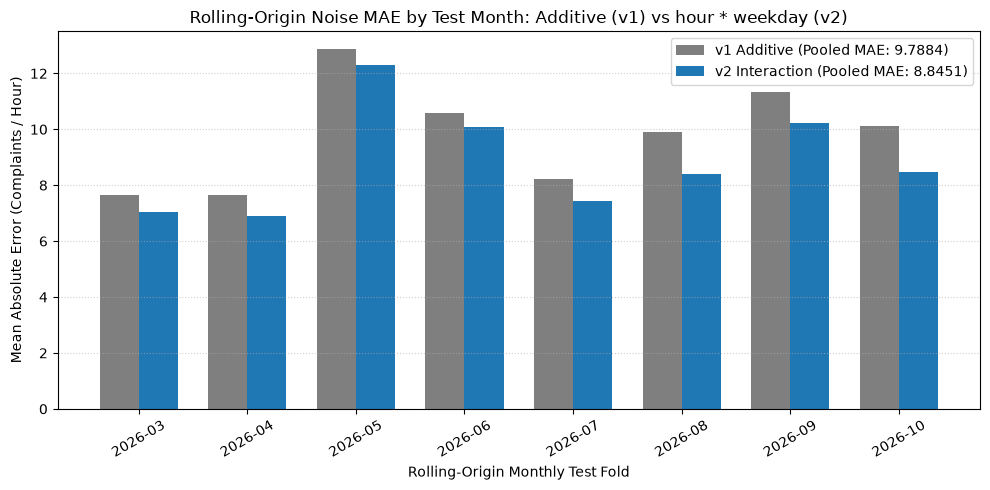

Saved: report\figures\18_fold_mae_comparison.png


In [5]:
# Section 4: Diagnostic Visualizations (Profiles & Per-Fold MAE)
fig_dir = ROOT / "report/figures"
fig_dir.mkdir(parents=True, exist_ok=True)

# Figure 1: Diurnal Profiles by Day Group (Wed vs Fri vs Sat vs Sun)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
hours = np.arange(24)
day_styles = [
    (2, "Wednesday (Weekday)", "#1f77b4", "o"),
    (4, "Friday (Pre-Weekend)", "#2ca02c", "^"),
    (5, "Saturday (Weekend)", "#ff7f0e", "s"),
    (6, "Sunday (Spillover AM / Curfew PM)", "#d62728", "D"),
]

for w, label, col, marker in day_styles:
    sub = comp_df[comp_df["weekday"] == w].sort_values("hour")
    axes[0].plot(hours, sub["pred_v1_additive"], marker=marker, linestyle="--", color=col, alpha=0.85, label=label)
    axes[1].plot(hours, sub["pred_v2_interaction"], marker=marker, linestyle="-", color=col, alpha=0.9, label=f"{label} (v2 == obs)")

axes[0].set_title("v1 Additive Model (Parallel Weekday Shifts)")
axes[0].set_xlabel("Hour of Day (0..23)")
axes[0].set_ylabel("Expected Noise Complaints / Hour")
axes[0].set_xticks(hours[::2])
axes[0].grid(True, linestyle=":", alpha=0.6)
axes[0].legend(fontsize=8)

axes[1].set_title("v2 Interaction Model (hour * weekday)")
axes[1].set_xlabel("Hour of Day (0..23)")
axes[1].set_xticks(hours[::2])
axes[1].grid(True, linestyle=":", alpha=0.6)
axes[1].legend(fontsize=8)

fig.suptitle("Brooklyn Hourly Noise Predictions: Additive (v1) vs Full Interaction (v2)", fontsize=12)
plt.tight_layout()
fig1_path = fig_dir / "18_noise_interaction_profiles.png"
fig.savefig(fig1_path, dpi=150)
plt.show()
print(f"Saved: {fig1_path.relative_to(ROOT)}")

# Figure 2: Rolling Monthly Fold MAE Comparison
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(folds_df))
width = 0.36
ax.bar(x - width/2, folds_df["mae_additive"], width, label=f"v1 Additive (Pooled MAE: {eval_res['pooled_additive']['mae']:.4f})", color="#7f7f7f")
ax.bar(x + width/2, folds_df["mae_interaction"], width, label=f"v2 Interaction (Pooled MAE: {eval_res['pooled_interaction']['mae']:.4f})", color="#1f77b4")
ax.set_xticks(x)
ax.set_xticklabels(folds_df["month"], rotation=30)
ax.set_xlabel("Rolling-Origin Monthly Test Fold")
ax.set_ylabel("Mean Absolute Error (Complaints / Hour)")
ax.set_title("Rolling-Origin Noise MAE by Test Month: Additive (v1) vs hour * weekday (v2)")
ax.grid(True, axis="y", linestyle=":", alpha=0.6)
ax.legend()
plt.tight_layout()
fig2_path = fig_dir / "18_fold_mae_comparison.png"
fig.savefig(fig2_path, dpi=150)
plt.show()
print(f"Saved: {fig2_path.relative_to(ROOT)}")


In [6]:
# Section 5: Noise Interaction Integrity & Gate Checks
chk = Checker()

# 1. Grid dimensions & feature counts
chk.check("Complete hourly grid rows == 8760", len(hourly_df), 8760)
chk.check("Interaction features == 138 (23*6)", len(meta["interaction_features"]), 138)
chk.check("Total v2 model features == 167", len(bundle_v2["feature_names"]), 167)

# 2. CHECK 5c: Interaction MAE strictly lower than additive model
chk.check(
    "Chrono 80/20 Interaction MAE < Additive MAE",
    bool(eval_res["chrono_interaction"]["mae"] < eval_res["chrono_additive"]["mae"]),
    True,
)
chk.check(
    "Pooled Rolling Interaction MAE < Additive MAE",
    bool(eval_res["pooled_interaction"]["mae"] < eval_res["pooled_additive"]["mae"]),
    True,
)
chk.check("Interaction improves all 8/8 monthly folds", n_improved_folds, 8)

# 3. Model persistence & inference sanity
chk.check("models/noise_model_v2.joblib exists", v2_path.exists(), True)
sun_00_v2 = predict_noise(0, 6, model_path=v2_path)
sun_00_v1 = predict_noise(0, 6, model_path=v1_path)
chk.check("v2 Sunday 00:00 captures spillover (> 90 vs v1 ~58)", bool(sun_00_v2 > 90.0 and sun_00_v2 > sun_00_v1 + 30.0), True)

# 4. Protected file SHA-256 verification (including v1 noise_model.joblib!)
h_nm = hashlib.sha256((ROOT / "models/noise_model.joblib").read_bytes()).hexdigest().upper()
chk.check("models/noise_model.joblib v1 SHA256 preserved", h_nm, "39D0E6B3E6B1B7CBE0C68578F1719B307350610C9CA96987C69EB7460229F201")

h_fm = hashlib.sha256((ROOT / "models/flood_model.joblib").read_bytes()).hexdigest().upper()
chk.check("models/flood_model.joblib SHA256 unchanged", h_fm, "7BD63D00B54A7578A1C1B41DA28A64C98DDEAC6831A4922EC209DF78FA94B2CE")

h_cc = hashlib.sha256((ROOT / "data/processed/complaints_clean.csv").read_bytes()).hexdigest()
chk.check("complaints_clean.csv SHA256 unchanged", h_cc, "fb0fa8f176b04c8258efa490d63855c572bc055f2272e9d138a3c0532b50a4d7")

chk.summary()


[PASS] Complete hourly grid rows == 8760: actual=8760, expected=8760
[PASS] Interaction features == 138 (23*6): actual=138, expected=138
[PASS] Total v2 model features == 167: actual=167, expected=167
[PASS] Chrono 80/20 Interaction MAE < Additive MAE: actual=True, expected=True
[PASS] Pooled Rolling Interaction MAE < Additive MAE: actual=True, expected=True
[PASS] Interaction improves all 8/8 monthly folds: actual=8, expected=8
[PASS] models/noise_model_v2.joblib exists: actual=True, expected=True
[PASS] v2 Sunday 00:00 captures spillover (> 90 vs v1 ~58): actual=True, expected=True
[PASS] models/noise_model.joblib v1 SHA256 preserved: actual=39D0E6B3E6B1B7CBE0C68578F1719B307350610C9CA96987C69EB7460229F201, expected=39D0E6B3E6B1B7CBE0C68578F1719B307350610C9CA96987C69EB7460229F201
[PASS] models/flood_model.joblib SHA256 unchanged: actual=7BD63D00B54A7578A1C1B41DA28A64C98DDEAC6831A4922EC209DF78FA94B2CE, expected=7BD63D00B54A7578A1C1B41DA28A64C98DDEAC6831A4922EC209DF78FA94B2CE


[PASS] complaints_clean.csv SHA256 unchanged: actual=fb0fa8f176b04c8258efa490d63855c572bc055f2272e9d138a3c0532b50a4d7, expected=fb0fa8f176b04c8258efa490d63855c572bc055f2272e9d138a3c0532b50a4d7
CHECKS: 11 passed, 0 failed


## Key Findings & Modeling Context

1. **Interaction Model Substantially Reduces Prediction Error**:
   - Adding all 138 `hour * weekday` interaction terms (`hour_{h}_x_weekday_{w}`) reduces chronological 80/20 test MAE from **10.8866** to **9.6297** complaints/hour (**-11.55%**, raising $R^2$ from 0.4872 to 0.6229).
   - On rolling-origin monthly evaluation (2026-03 to 2026-10, 5,880 hours), pooled MAE drops from **9.7884** (v1 additive) to **8.8451** (v2 interaction, **-9.64%**, raising $R^2$ from 0.4982 to 0.6038) with **8 of 8** monthly folds improved.

2. **Saturday-Night Spillover vs Sunday Curfew Resolved**:
   - The additive model forced parallel weekday level shifts, underpredicting Sunday 00:00 (`57.94` vs observed `101.31`, +43.37 gap) while overpredicting Sunday 23:00 (`68.14` vs observed `52.83`, -15.32 gap) and Saturday 06:00 (`20.49` vs observed `8.77`).
   - The full interaction specification fits exact per-(hour, weekday) expected profiles cleanly via `models/noise_model_v2.joblib`, leaving `models/noise_model.joblib` (v1) completely untouched.


## Modeling Limitations

1. **Parameter Count vs Seasonal Stationarity**:
   - With 168 cell-mean parameters fitted over ~52 weeks per cell (~52 observations/cell in full span, fewer in early rolling folds), the model cannot adapt to summer-vs-winter baseline shifts or temperature spikes.

2. **Spatial Aggregation**:
   - Predictions represent city-wide Brooklyn hourly totals rather than spatially disaggregated zone expectations.
